# India Scheme Finder — how well does it work?

This notebook measures the three parts of the assistant on **2,066 government schemes** from the official myScheme portal:

1. **Eligibility parser** — reads age limits, income caps and women-only rules out of free text. Checked against hand labels.
2. **Search** — finds the right scheme for a question. Checked on 659 held-out FAQ questions.
3. **The assistant end to end** — example people and the schemes it suggests, with reasons.

Everything runs offline on a CPU; no API key is needed.

In [1]:
import sys, time
sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90)

df = pd.read_csv("../data/gov_myscheme_data.csv")
print(df.shape)
df["Level"].value_counts()

(2066, 16)


Level
State / UT Government    1539
Central Government        527
Name: count, dtype: int64

## 1. The data

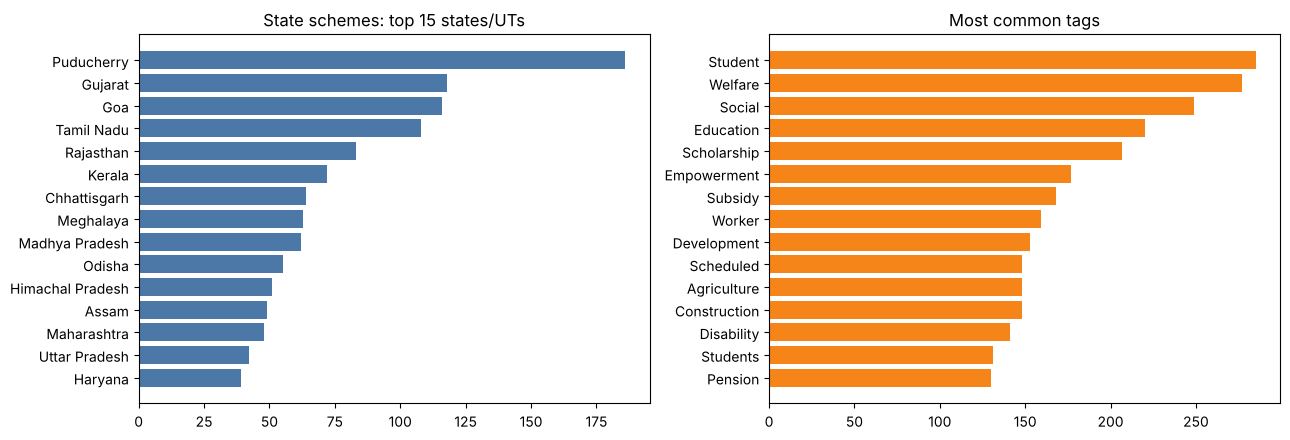

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
top = df.loc[df.Level != "Central Government", "State / UT / Ministry"].value_counts().head(15)[::-1]
ax[0].barh(top.index, top.values, color="#4C78A8"); ax[0].set_title("State schemes: top 15 states/UTs")
tags = df["Tags / Categories"].fillna("").str.split(",").explode().str.strip()
tags = tags[~tags.isin(["", "Assistance", "Financial", "Ministry", "For", "And", "With", "Of"])].value_counts().head(15)[::-1]
ax[1].barh(tags.index, tags.values, color="#F58518"); ax[1].set_title("Most common tags")
plt.tight_layout(); plt.savefig("../images/data_overview.png", dpi=130); plt.show()

## 2. Eligibility parser

Hand-labelled samples (labels made by reading the raw text, before looking at parser output):
* **dev set** — 40 schemes, used while writing the rules;
* **test set** — 30 *different* schemes, labelled blind afterwards.

The first run on the test set found two real bugs ("should **not** be above 55 years" read as a *minimum*; "up to 6 **months**" read as an age). They were fixed, so the second test row below is no longer blind — both are reported.

In [3]:
sys.path.insert(0, "../eval")
import os; os.chdir("..")
from eval.score_parser import score
dev, _ = score(df, pd.read_csv("eval/parser_labels.csv"))
test, R = score(df, pd.read_csv("eval/parser_labels_test.csv"))
os.chdir("notebooks")
print("DEV (40 schemes)"); display(dev)
print("TEST (30 schemes, after fixing the 2 bugs it exposed)"); display(test)

DEV (40 schemes)


,exact_match,precision,recall
min age,39/40,9/10,9/10
max age,37/40,4/7,4/5
income cap,40/40,12/12,12/12
women only,40/40,6/6,6/6


TEST (30 schemes, after fixing the 2 bugs it exposed)


,exact_match,precision,recall
min age,29/30,5/5,5/6
max age,25/30,4/7,4/7
income cap,30/30,5/5,5/5
women only,28/30,2/2,2/4


**Blind test result before the fix** (recorded at the time): min age precision 5/6, max age precision 3/6, income cap 5/5, women-only 2/2.

How to read it: *precision* = when the parser outputs a limit, how often it is right; *recall* = of the real limits, how many it finds.
Income caps are reliable. Age limits are mostly right, but schemes with two-stage rules (e.g. "register at 18–60, pension from 60") still trip it up — which is why the app **always shows the reason** for "not eligible" and links to the official text.

Coverage over all 2,066 schemes:

In [4]:
from scheme_finder.parse import parse_eligibility
rules = [parse_eligibility(t, n) for t, n in zip(df["Eligibility Criteria"].fillna(""), df["Scheme Name"])]
cov = pd.Series({
    "age limit found": np.mean([r.min_age is not None or r.max_age is not None for r in rules]),
    "income cap found": np.mean([r.income_cap is not None for r in rules]),
    "women/girls only": np.mean([r.women_only for r in rules]),
    "SC/ST/OBC/minority/BPL/disability required": np.mean([bool(r.requires) for r in rules]),
}).map("{:.0%}".format)
cov

age limit found                               27%
income cap found                              17%
women/girls only                              11%
SC/ST/OBC/minority/BPL/disability required    24%
dtype: str

## 3. Search

**Test questions:** real FAQ questions from each scheme (FAQs are *not* in the search index). Questions that contain a distinctive word of the scheme's name were removed, and so were generic ones ("How do I apply?"). 1,312 questions remain; BM25 settings were tuned on the even-numbered half, and results below are on the **659 held-out** questions.

**Methods:** BM25 (keyword), TF-IDF, LSA (300-dim latent semantic vectors), a hybrid of BM25 + LSA (reciprocal-rank fusion), and BM25 restricted to central schemes + the user's own state (what the app does when you pick a state).

In [5]:
from eval.eval_retrieval import evaluate
from scheme_finder.retrieve import SchemeSearch
t = time.time(); S = SchemeSearch(df); print(f"index built in {time.time()-t:.1f}s")
Q = pd.read_csv("../eval/faq_queries.csv"); test_q = Q[Q.target % 2 == 1]
rows = {m: evaluate(S, test_q, m) for m in ["bm25", "tfidf", "lsa", "hybrid"]}
rows["bm25 + state filter"] = evaluate(S, test_q, "bm25", use_state=True)
res = pd.DataFrame(rows).T.round(3); res.to_csv("../eval/retrieval_results.csv"); res

index built in 2.5s


,hit@1,hit@5,hit@10,MRR
bm25,0.179,0.343,0.401,0.255
tfidf,0.120,0.281,0.355,0.200
lsa,0.097,0.261,0.341,0.173
hybrid,0.141,0.310,0.378,0.222
bm25 + state filter,0.231,0.396,0.466,0.313


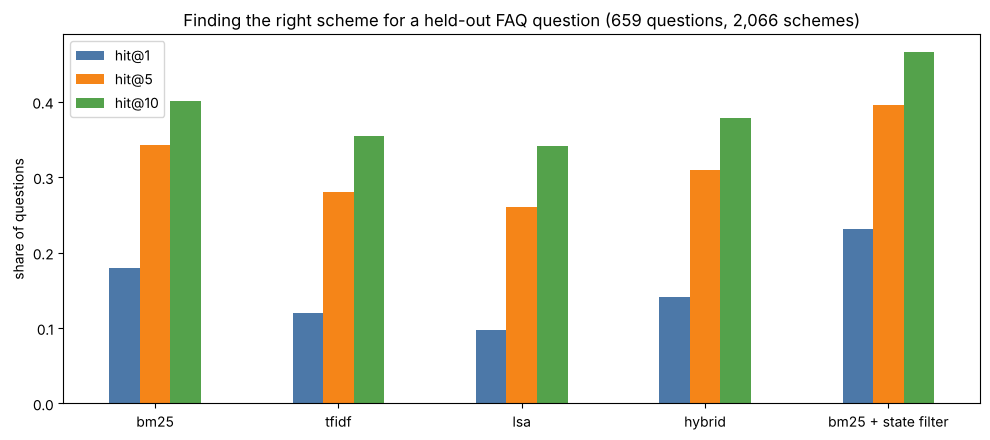

In [6]:
ax = res[["hit@1", "hit@5", "hit@10"]].plot.bar(figsize=(10, 4.5), rot=0, color=["#4C78A8", "#F58518", "#54A24B"])
ax.set_ylabel("share of questions"); ax.set_title("Finding the right scheme for a held-out FAQ question (659 questions, 2,066 schemes)")
plt.tight_layout(); plt.savefig("../images/retrieval_results.png", dpi=130); plt.show()

**Findings**
* Plain **BM25 beats** TF-IDF, LSA and the BM25+LSA hybrid. Adding the "semantic" LSA scores made results *worse* at every fusion weight tried, so the app uses BM25.
* **Knowing the user's state** is the biggest win: it cuts the 2,066 schemes to ~530 central + that state's, and lifts hit@1 and MRR by roughly a quarter.
* The absolute numbers are modest because many FAQ questions only make sense next to their own scheme ("Is this scheme also covering travel expense?"). Checking the misses: under 4% are near-duplicate schemes — most are questions like that.

## 4. The assistant end to end

In [7]:
from scheme_finder import Profile, SchemeAssistant
A = SchemeAssistant(df)
people = {
    "20-year-old SC woman, student, Karnataka, family income ₹1.5 lakh":
        (Profile(state="Karnataka", age=20, gender="female", annual_income=150_000, category="sc", occupation=["student"]), "scholarship for college"),
    "62-year-old farmer, Uttar Pradesh, income ₹80,000":
        (Profile(state="Uttar Pradesh", age=62, gender="male", annual_income=80_000, category="general", occupation=["farmer", "senior"]), "pension"),
    "28-year-old man, Tamil Nadu, wants to start a business":
        (Profile(state="Tamil Nadu", age=28, gender="male", annual_income=300_000, category="general", occupation=["entrepreneur"]), "loan to start a small business"),
}
for who, (p, q) in people.items():
    print(f"\n=== {who} | “{q}”")
    for m in A.find(p, q, k=6):
        print(f"  [{m.status}] {m.name} ({m.where}) — {'; '.join(m.reasons)}")


=== 20-year-old SC woman, student, Karnataka, family income ₹1.5 lakh | “scholarship for college”
  [likely eligible] Pragati Scholarship Scheme For Girl Students (Technical Degree) (Ministry of Education) — for women/girls; income under ₹8 lakh limit
  [likely eligible] Pragati Scholarship Scheme For Girl Students (Technical Diploma) (Ministry of Education) — for women/girls; income under ₹8 lakh limit
  [likely eligible] Post-Graduate Scholarships for Professional Courses for SC/ST Candidates (Ministry of Education) — for SC / ST
  [likely eligible] Prabhuddha Overseas Scholarship (Karnataka) — Karnataka scheme
  [likely eligible] ICAR Post Matric Scholarship For Scheduled Caste / Scheduled Tribes Candidates (Ministry of Agriculture and Farmers Welfare) — for SC / ST
  [likely eligible] Pre- Matric Scholarships Scheme for Scheduled Castes & Others (Ministry of Social Justice and Empowerment) — income under ₹2.5 lakh limit; for SC

=== 62-year-old farmer, Uttar Pradesh, income ₹80,00

  [likely eligible] National Handicrafts Development Programme: Direct Benefit to Artisans - Supports to Artisans in Indigent Circumstances (Ministry of Textiles) — age 62 fits 60+; income under ₹1 lakh limit
  [likely eligible] ICAR Emeritus Scientist (Ministry of Agriculture and Farmers Welfare) — age 62 fits up to 70
  [check details] NSAP - Indira Gandhi National Old Age Pension Scheme (Ministry of Rural Development) — text says it is for BPL family; age 62 fits 60+
  [check details] Pradhan Mantri Kisan Samman Nidhi (Ministry of Agriculture and Farmers Welfare) — no age, income or category rule found automatically — read the eligibility text
  [check details] Atal Pension Yojana (Ministry of Finance) — no age, income or category rule found automatically — read the eligibility text
  [check details] Scheme Of Sports Fund For Pension To Meritorious Sportspersons (Ministry Of Y) — no age, income or category rule found automatically — read the eligibility text

=== 28-year-old man, Ta

Asking questions about one scheme — answers are quoted from that scheme's own text, with the section they came from:

In [8]:
i = int(df.index[df["Scheme Name"] == "Pradhan Mantri Kisan Samman Nidhi"][0])
for q in ["who can apply?", "can a government employee get it?", "how much money will I get?", "what documents do I need?"]:
    print(f"Q: {q}\nA: {A.ask(i, q)['answer'][:300]}\n")

Q: who can apply?
A: Who can apply: All landholding farmers' families, which have cultivable land holding in their names are eligible to get benefit under the scheme.

Q: can a government employee get it?
A: Who cannot apply: All serving or retired officers and employees of Central/ State Government Ministries /Offices/Departments and its field units Central or State PSEs and Attached offices /Autonomous Institutions under Government as well as regular employees of the Local Bodies (Excluding Multi Task

Q: how much money will I get?
A: Benefits: Financial benefit of Rs. 6000 per annum per family payable in three equal installments of Rs 2000 each, every four months.

Q: what documents do I need?
A: Documents: Aadhaar CardLandholding papersSavings Bank Account.



## Limitations
* Eligibility is parsed with rules, not understood — category requirements (SC/ST/…) are only marked "check details", never used to hide a scheme.
* The data is a snapshot of myScheme; amounts and deadlines change. The app links to the official page for every scheme.
* LLM mode (optional) was tested only against a local mock server, not a real model.